# Industry Project: Keeping an Ad-Click Model Fresh on a Data Stream (Production-Style)

> **Who is this notebook for?** Beginners who have trained a model once with `fit()` and wonder what happens when **new data arrives every hour and the world keeps changing**.
> Every step is explained in plain English and almost every line of code has a comment.

---

### How this notebook is different from `01_online_learning.ipynb`

| `01_online_learning.ipynb` | This notebook |
|---|---|
| Online SGD and Passive-Aggressive from scratch, `river` library | Plain **scikit-learn** `partial_fit`, the tool most teams already have |
| Small numeric toy streams | A realistic ad-impression stream: high-cardinality categories, new publishers, daily cycles |
| Shows that drift exists | Compares **4 update strategies** under drift: static, scheduled retrain, online, drift-triggered |
| Model quality only | **Safeguards**: learning-rate choice, data validation, snapshot **rollback**, **shadow** deployment, saving, serving, tests |

---

### The business problem

You work for an **ad network**. Every time a mobile app or website shows an ad slot, your system must predict the probability that the user **clicks** (the *click-through rate*, CTR). The prediction decides how much the advertiser bids, so:

- predictions must be **well calibrated** (a predicted 10% should really mean 10%), otherwise you over- or under-pay;
- data arrives **continuously**: ~1,500 impressions per hour in our simulation (millions in real life);
- the world **changes**: publishers redesign their apps, new publishers join, an app category becomes trendy. A model trained last week slowly becomes wrong. This is **concept drift**.

**Your job:** decide *how* to keep the model up to date, and make the updating process **safe** (a bad batch of data must not break production).

### Table of Contents
1. Setup and config
2. The data stream (simulated ad impressions with drift)
3. Features for streams: the hashing trick + a fixed scaler
4. Prequential evaluation: test-then-train
5. Strategy A: static model (train once)
6. Strategy B: scheduled retraining (every night)
7. Strategy C: online updates with `partial_fit`
8. Strategy D: drift detection (Page-Hinkley) + triggered retraining
9. Compare the strategies
10. Safeguard 1: choosing the learning rate
11. Safeguard 2: data validation and rollback
12. Safeguard 3: shadow deployment before promotion
13. Save the model with its metadata
14. Serve predictions with input validation
15. Automated sanity tests
16. Summary, exercises and resources

---
## 1. Setup and config

In [1]:
import copy                      # deep copies = model "snapshots" for rollback
import json
import logging
import tempfile
import time
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.sparse import csr_matrix, hstack, vstack     # sparse matrices: most features are 0
from sklearn.feature_extraction import FeatureHasher   # the hashing trick
from sklearn.linear_model import SGDClassifier         # supports partial_fit (incremental learning)
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("stream")


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    n_days: int = 14                  # length of the simulated stream
    events_per_hour: int = 1_500      # one "mini-batch" = one hour of impressions
    warmup_hours: int = 72            # first 3 days: initial training data
    drift_hour: int = 7 * 24          # day 7: publishers change, a category becomes trendy
    new_sites_hour: int = 10 * 24     # day 10: new publishers join the network
    hash_features: int = 2 ** 18      # size of the hashed feature space (262,144 columns)
    learning_rate: float = 0.02       # constant SGD step size for online updates
    l2: float = 1e-5                  # regularization strength (alpha in SGDClassifier)
    retrain_window_hours: int = 72    # nightly retrain uses the last 3 days
    retrain_epochs: int = 5           # passes over the window when (re)training from scratch


CFG = Config()
N_HOURS = CFG.n_days * 24
print(CFG)

Config(random_state=42, n_days=14, events_per_hour=1500, warmup_hours=72, drift_hour=168, new_sites_hour=240, hash_features=262144, learning_rate=0.02, l2=1e-05, retrain_window_hours=72, retrain_epochs=5)


---
## 2. The data stream (simulated ad impressions with drift)

In production the events come from a message queue such as **Kafka** or **Kinesis**, and click labels are joined a few minutes after the impression:

```python
# Real-life version (not run here)
# for message in kafka_consumer:                 # one impression at a time
#     buffer.append(json.loads(message.value))
#     if hour_has_passed(): yield pd.DataFrame(buffer); buffer.clear()
```

We simulate 14 days of hourly batches. Each impression has: the **site/app id** (300 publishers, very uneven popularity), the **app category**, **device**, **banner position**, **hour of day**, the user's **past clicks** and the advertiser's **bid price**. The hidden click behaviour changes on purpose:

| When | What changes | Real-world cause |
|---|---|---|
| Day 7 (hour 168) | Half of the publishers get a new click pattern; "games" becomes much more clickable, "shopping" less | App redesigns, a viral game, a seasonal campaign ending |
| Day 10 (hour 240) | 25% of traffic comes from **100 brand-new publishers** the model has never seen | Sales team onboards new partners |
| Always | Daily cycle (people click more in the evening), 3% missing device info | Normal life, SDK bugs |

In [2]:
class AdStreamSimulator:
    """Generates one hour of ad impressions at a time, with sudden drift and new publishers."""

    CATEGORIES = ["news", "games", "shopping", "sports", "video", "finance", "travel"]

    def __init__(self, cfg: Config):
        self.cfg = cfg
        self.rng = np.random.default_rng(cfg.random_state)
        n_sites = 300
        self.site_popularity = self.rng.dirichlet(np.ones(n_sites) * 0.5)     # a few huge publishers
        self.site_category = self.rng.choice(self.CATEGORIES, n_sites)
        self.site_effect = self.rng.normal(0, 0.8, n_sites)                  # how clickable each site is
        self.site_effect_after = self.site_effect.copy()
        changed = self.rng.choice(n_sites, 150, replace=False)               # half the sites change at drift
        self.site_effect_after[changed] = self.rng.normal(0, 0.8, 150)
        self.cat_effect = dict(zip(self.CATEGORIES, self.rng.normal(0, 0.5, len(self.CATEGORIES))))
        self.cat_effect_after = dict(self.cat_effect, games=self.cat_effect["games"] + 1.0,
                                     shopping=self.cat_effect["shopping"] - 0.8)
        self.new_site_effect = self.rng.normal(0.3, 0.8, 100)
        self.device_effect = {"ios": 0.2, "android": 0.0, "desktop": -0.3}

    def hour(self, h: int) -> pd.DataFrame:
        rng, n, drifted = self.rng, self.cfg.events_per_hour, h >= self.cfg.drift_hour
        sites = rng.choice(len(self.site_popularity), n, p=self.site_popularity)
        site_id = np.array([f"site_{s}" for s in sites], dtype=object)
        site_eff = (self.site_effect_after if drifted else self.site_effect)[sites].copy()
        if h >= self.cfg.new_sites_hour:                                     # new publishers join
            is_new = rng.random(n) < 0.25
            new_ids = rng.integers(0, 100, is_new.sum())
            site_id[is_new] = [f"newsite_{s}" for s in new_ids]
            site_eff[is_new] = self.new_site_effect[new_ids]
        category = self.site_category[sites]
        device = rng.choice(["ios", "android", "desktop"], n, p=[0.35, 0.45, 0.20])
        banner_pos = rng.choice([0, 1, 2], n, p=[0.6, 0.3, 0.1])               # 0 = top of the page
        past_clicks = rng.poisson(1.0, n)
        bid_price = rng.lognormal(0, 0.5, n).round(3)
        cat_eff = pd.Series(category).map(self.cat_effect_after if drifted else self.cat_effect).values
        logit = (-2.4 + site_eff + cat_eff + pd.Series(device).map(self.device_effect).values
                 - 0.4 * banner_pos + 0.35 * past_clicks + 0.3 * np.log(bid_price)
                 + 0.3 * np.sin(2 * np.pi * (h % 24) / 24))                  # daily cycle
        clicked = rng.binomial(1, 1 / (1 + np.exp(-logit)))
        df = pd.DataFrame({"hour_index": h, "site_id": site_id, "app_category": category,
                           "device": device, "banner_pos": banner_pos, "hour_of_day": h % 24,
                           "past_clicks_7d": past_clicks, "bid_price": bid_price, "clicked": clicked})
        df.loc[rng.random(n) < 0.03, "device"] = None                       # SDK sometimes misses the device
        return df


simulator = AdStreamSimulator(CFG)
stream = [simulator.hour(h) for h in range(N_HOURS)]                       # list of hourly DataFrames
log.info("Generated %d hourly batches, %s impressions", len(stream), f"{sum(map(len, stream)):,}")
hourly_ctr = pd.Series([b["clicked"].mean() for b in stream])
print(f"Average CTR: {hourly_ctr.mean():.2%} | min hour {hourly_ctr.min():.2%} | max hour {hourly_ctr.max():.2%}")
stream[0].head()

2026-10-21 17:35:35,704 | INFO | Generated 336 hourly batches, 504,000 impressions


Average CTR: 17.97% | min hour 12.33% | max hour 25.33%


,hour_index,site_id,app_category,device,banner_pos,hour_of_day,past_clicks_7d,bid_price,clicked
0,0,site_221,finance,android,1,0,0,0.492,0
1,0,site_279,games,android,1,0,0,0.563,0
2,0,site_151,news,ios,1,0,3,1.602,0
3,0,site_183,travel,ios,0,0,1,0.806,1
4,0,site_261,news,ios,1,0,1,0.554,0


---
## 3. Features for streams: the hashing trick + a fixed scaler

**Problem:** with batch learning you build a vocabulary of all site ids up front (`OneHotEncoder`). In a stream, **new site ids appear all the time** (day 10!), and the model's input size must never change.

**Solution: the hashing trick.** `FeatureHasher` turns each `"column=value"` string into a column number using a hash function, inside a fixed space of 2^18 columns. A brand-new value like `site_id=newsite_42` simply lands in some column; nothing crashes and nothing needs to be re-fitted. Collisions (two values sharing a column) are rare in a space this big and cost very little accuracy. This is how large ad systems (and Vowpal Wabbit) handle billions of ids.

We also add one **cross feature** (`site × device`): linear models can't discover interactions on their own.

**Numeric features** (past clicks, log of bid price) need **scaling** for SGD. We fit a `StandardScaler` on the warm-up data and then **freeze** it. (`StandardScaler` also has `partial_fit`, but if the scaling keeps moving, the meaning of every learned weight silently shifts under the model. Teams update it only together with a full retrain.)

In [3]:
CATEGORICAL = ["site_id", "app_category", "device", "banner_pos", "hour_of_day"]
NUMERIC = ["past_clicks_7d", "bid_price"]
hasher = FeatureHasher(n_features=CFG.hash_features, input_type="string", alternate_sign=False)


def numeric_block(df: pd.DataFrame) -> pd.DataFrame:
    """Numeric inputs; prices are skewed, so we use their logarithm."""
    return pd.DataFrame({"past_clicks_7d": df["past_clicks_7d"], "log_bid": np.log(df["bid_price"])})


def to_tokens(df: pd.DataFrame) -> list[list[str]]:
    """Turn each row into strings like 'site_id=site_7'. Missing values become an explicit token."""
    values = df[CATEGORICAL].astype(object).where(df[CATEGORICAL].notna(), "missing").astype(str).values
    return [[f"{c}={v}" for c, v in zip(CATEGORICAL, row)] + [f"site_x_device={row[0]}|{row[2]}"]
            for row in values]


def featurize(df: pd.DataFrame, scaler: StandardScaler) -> csr_matrix:
    """Hashed categorical features + scaled numeric features, as one sparse matrix."""
    hashed = hasher.transform(to_tokens(df))
    scaled = csr_matrix(scaler.transform(numeric_block(df)))
    return hstack([hashed, scaled]).tocsr()


scaler = StandardScaler().fit(numeric_block(pd.concat(stream[: CFG.warmup_hours])))   # warm-up only, then frozen
start = time.time()
X_stream = [featurize(b, scaler) for b in stream]                     # pre-compute once to save time
y_stream = [b["clicked"].values for b in stream]
print(f"Featurized {len(X_stream)} batches in {time.time() - start:.1f}s | matrix shape per batch {X_stream[0].shape}"
      f" | non-zeros per row {X_stream[0].getrow(0).nnz}")

Featurized 336 batches in 15.3s | matrix shape per batch (1500, 262146) | non-zeros per row 8


---
## 4. Prequential evaluation: test-then-train

With streams we can't do a normal train/test split, because the future is different from the past. The standard is **prequential** ("predictive sequential") evaluation:

1. a new batch arrives → the model **predicts** it first (this is the honest test: the model has never seen these events);
2. we record the metrics;
3. *then* the model may **learn** from the batch.

This is exactly what happens in production, so the metric is what users would have experienced.

**Metrics.** We track **AUC** (ranking quality) and **normalized entropy (NE)**, the metric Facebook's ads team made popular: the log-loss divided by the log-loss of a dumb model that always predicts the batch's average CTR.
- NE < 1: better than the dumb model; lower is better.
- Unlike raw log-loss, NE does **not** move just because the CTR is higher in the evening, which makes it a stable signal for drift detection.

In [4]:
def normalized_entropy(y: np.ndarray, p: np.ndarray) -> float:
    """Log-loss of the model divided by the log-loss of always predicting the base rate."""
    base = np.clip(y.mean(), 1e-6, 1 - 1e-6)
    baseline_loss = -(base * np.log(base) + (1 - base) * np.log(1 - base))
    return log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]) / baseline_loss


def evaluate_batch(model, X, y) -> dict:
    p = model.predict_proba(X)[:, 1]
    return {"ne": normalized_entropy(y, p), "auc": roc_auc_score(y, p),
            "pred_ctr": p.mean(), "true_ctr": y.mean()}


def new_sgd(learning_rate: str = "constant", eta0: float = CFG.learning_rate) -> SGDClassifier:
    """Logistic regression trained by SGD. loss='log_loss' gives probabilities."""
    return SGDClassifier(loss="log_loss", alpha=CFG.l2, learning_rate=learning_rate, eta0=eta0,
                         random_state=CFG.random_state)


def train_from_scratch(hours: range, eta0: float = CFG.learning_rate) -> SGDClassifier:
    """Batch-style training on a window of hours (several shuffled passes with partial_fit)."""
    model = new_sgd(eta0=eta0)
    X, y = vstack([X_stream[h] for h in hours]), np.concatenate([y_stream[h] for h in hours])
    rng = np.random.default_rng(CFG.random_state)
    for _ in range(CFG.retrain_epochs):
        order = rng.permutation(len(y))                               # shuffle each epoch
        model.partial_fit(X[order], y[order], classes=[0, 1])
    return model


EVAL_HOURS = range(CFG.warmup_hours, N_HOURS)                        # we evaluate from day 4 to day 14

---
## 5. Strategy A: static model (train once)

The most common setup in companies that are new to ML: train on a big batch once, deploy, forget. It is our **baseline**.

In [5]:
initial_model = train_from_scratch(range(CFG.warmup_hours))           # days 1-3


def run_static(model) -> pd.DataFrame:
    return pd.DataFrame([evaluate_batch(model, X_stream[h], y_stream[h]) | {"hour": h} for h in EVAL_HOURS])


results = {"A: static": run_static(initial_model)}
results["A: static"].groupby(results["A: static"]["hour"] >= CFG.drift_hour)[["ne", "auc"]].mean() \
    .rename(index={False: "before drift", True: "after drift"}).round(4)

,ne,auc
hour,,
before drift,0.8839,0.7421
after drift,0.9485,0.6854


As expected, the static model is fine until day 7 and then gets clearly worse (higher NE, lower AUC). Nobody notices unless somebody monitors it.

---
## 6. Strategy B: scheduled retraining (every night)

The classic fix: an orchestrator (Airflow, Prefect, cron, see `../../15_MLOps/03_pipeline_orchestration/`) retrains the model **from scratch every night at midnight** on the last 3 days. Simple, reproducible, easy to audit, and the most common setup in industry.

In [6]:
def run_nightly_retrain() -> pd.DataFrame:
    model, rows = initial_model, []
    for h in EVAL_HOURS:
        if h % 24 == 0 and h > CFG.warmup_hours:                       # midnight: retrain on the last window
            model = train_from_scratch(range(h - CFG.retrain_window_hours, h))
        rows.append(evaluate_batch(model, X_stream[h], y_stream[h]) | {"hour": h})
    return pd.DataFrame(rows)


results["B: nightly retrain"] = run_nightly_retrain()
log.info("Nightly retrain done")

2026-10-21 17:36:10,164 | INFO | Nightly retrain done


---
## 7. Strategy C: online updates with `partial_fit`

Instead of starting over, we **continue training** the existing model on every new hour of data: one call to `partial_fit` per batch. The model adapts within hours instead of days, and each update takes milliseconds.

With a **constant learning rate**, recent data always has a fixed influence, so old patterns are gradually "forgotten". That is exactly what we want when the world changes (Section 10 shows what goes wrong with other choices).

In [7]:
def run_online(model, eta0: float | None = None) -> pd.DataFrame:
    """Prequential loop: predict the batch, record metrics, THEN learn from it."""
    model = copy.deepcopy(model)                                        # never modify the caller's model
    if eta0 is not None:
        model.set_params(eta0=eta0)
    rows = []
    for h in EVAL_HOURS:
        rows.append(evaluate_batch(model, X_stream[h], y_stream[h]) | {"hour": h})   # 1. test
        model.partial_fit(X_stream[h], y_stream[h])                                   # 2. train
    return pd.DataFrame(rows)


results["C: online (hourly)"] = run_online(initial_model)
log.info("Online run done")

2026-10-21 17:36:25,148 | INFO | Online run done


---
## 8. Strategy D: drift detection (Page-Hinkley) + triggered retraining

A middle way: keep the stable, audited static model, but **watch** its NE and retrain only **when something changes**. After an alarm we wait 12 hours to collect data from the *new* world, and retrain on that data only (training on the old world would teach the model the old patterns again).

The **Page-Hinkley test** is a classic, tiny change detector. It keeps a running mean of the monitored value and a cumulative sum of how much each new value is *above* that mean (minus a small tolerance `delta`). When that sum rises more than `threshold` above its lowest point, it raises an alarm. In plain words: *"the error has been consistently higher than usual for a while"*.

(The `river` library has ready-made detectors such as `PageHinkley` and `ADWIN`, used in `01_online_learning.ipynb`; written by hand it's 10 lines.)

In [8]:
class PageHinkley:
    """Detects an increase in the mean of a stream of numbers (here: hourly NE)."""

    def __init__(self, delta: float = 0.01, threshold: float = 0.2):
        self.delta, self.threshold = delta, threshold   # tolerance per step, alarm level
        self.reset()

    def reset(self):
        self.n, self.mean, self.cum, self.cum_min = 0, 0.0, 0.0, 0.0

    def update(self, value: float) -> bool:
        self.n += 1
        self.mean += (value - self.mean) / self.n            # running mean of everything seen
        self.cum += value - self.mean - self.delta           # how far above "normal" we keep landing
        self.cum_min = min(self.cum_min, self.cum)
        return (self.cum - self.cum_min) > self.threshold    # True = drift alarm


def run_drift_triggered(collect_hours: int = 12, lookback: int = 3) -> tuple[pd.DataFrame, list[int]]:
    """Static model + Page-Hinkley. After an alarm, collect `collect_hours` of NEW data, then retrain on it."""
    model, detector, rows, alarms, retrain_at = initial_model, PageHinkley(), [], [], None
    for h in EVAL_HOURS:
        metrics = evaluate_batch(model, X_stream[h], y_stream[h])
        rows.append(metrics | {"hour": h})
        if retrain_at is None and detector.update(metrics["ne"]):   # alarm: the world has changed
            alarms.append(h)
            retrain_at = h + collect_hours                            # wait for enough post-change data
        if retrain_at is not None and h == retrain_at:
            # train only on data from (shortly before) the alarm onwards: old-world data would mislead the model
            model = train_from_scratch(range(alarms[-1] - lookback, h + 1))
            detector.reset()
            retrain_at = None
    return pd.DataFrame(rows), alarms


results["D: drift-triggered retrain"], drift_alarms = run_drift_triggered()
print("Drift alarms at hours:", drift_alarms, f"(true changes at {CFG.drift_hour} and {CFG.new_sites_hour})")

Drift alarms at hours: [171] (true changes at 168 and 240)


---
## 9. Compare the strategies

We plot a **24-hour rolling average** of the prequential NE and AUC (single hours are noisy) and summarise three periods: before the drift, the first 24 hours after it, and the last 3 days (after the new publishers joined).

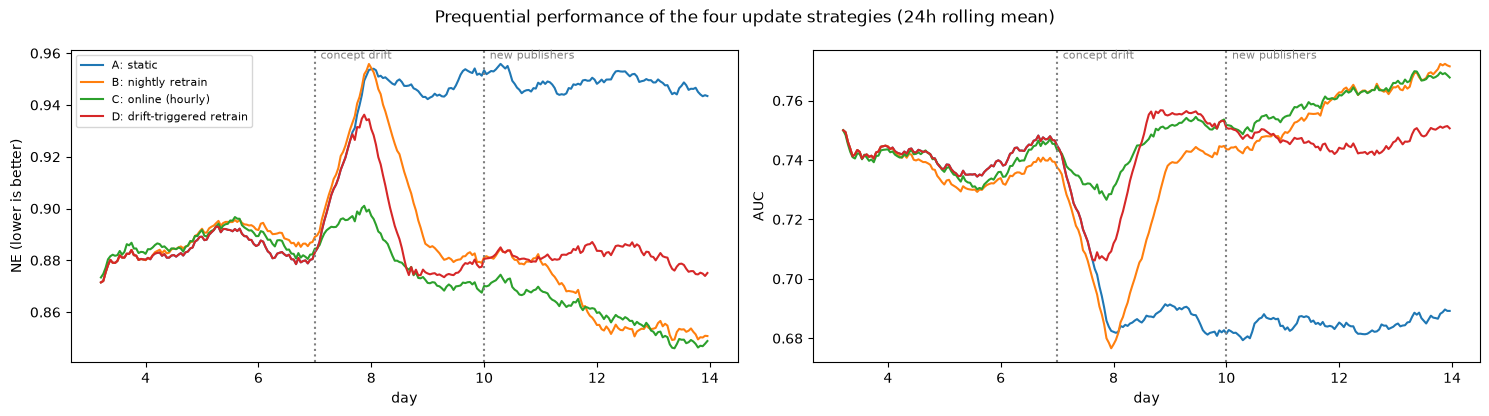

,NE | before drift (days 4-7),NE | first 24h after drift,NE | last 3 days,NE | whole evaluation,AUC | last 3 days
A: static,0.8839,0.9535,0.9476,0.9250,0.6858
B: nightly retrain,0.8876,0.9558,0.8536,0.8832,0.7660
C: online (hourly),0.8864,0.8996,0.8543,0.8744,0.7648
D: drift-triggered retrain,0.8839,0.9345,0.8807,0.8860,0.7465


In [9]:
def plot_runs(runs: dict, title: str, metrics=("ne", "auc")):
    fig, axes = plt.subplots(1, len(metrics), figsize=(15, 4.2))
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        for name, df in runs.items():
            ax.plot(df["hour"] / 24, df[metric].rolling(24, min_periods=6).mean(), label=name)
        for event, label in [(CFG.drift_hour, "concept drift"), (CFG.new_sites_hour, "new publishers")]:
            ax.axvline(event / 24, color="grey", ls=":")
            ax.text(event / 24 + 0.1, ax.get_ylim()[1], label, va="top", fontsize=8, color="grey")
        ax.set_xlabel("day"); ax.set_ylabel(metric.upper() + (" (lower is better)" if metric == "ne" else ""))
    np.atleast_1d(axes)[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()


def period_summary(runs: dict) -> pd.DataFrame:
    periods = {"before drift (days 4-7)": lambda h: h < CFG.drift_hour,
               "first 24h after drift": lambda h: (h >= CFG.drift_hour) & (h < CFG.drift_hour + 24),
               "last 3 days": lambda h: h >= N_HOURS - 72,
               "whole evaluation": lambda h: h >= 0}
    rows = {}
    for name, df in runs.items():
        rows[name] = {f"NE | {p}": df.loc[f(df["hour"]), "ne"].mean() for p, f in periods.items()} | \
                     {"AUC | last 3 days": df.loc[df["hour"] >= N_HOURS - 72, "auc"].mean()}
    return pd.DataFrame(rows).T.round(4)


plot_runs(results, "Prequential performance of the four update strategies (24h rolling mean)")
comparison = period_summary(results)
comparison

**How to read this** (lower NE is better):
- **A, static:** good until day 7, then clearly worse, and it never recovers.
- **B, nightly retrain:** in the first 24 hours after the drift it is as bad as the static model (it only learns at the next midnight, and its 3-day window still contains old-world data for a while). By the last 3 days it has fully caught up.
- **C, online:** adapts within hours. It is clearly the best in the first day after the drift and has the best NE over the whole evaluation, at almost no compute cost. In the long run (last 3 days) B and C are equally good.
- **D, drift-triggered:** the detector fired a few hours after the change (see the alarm hours printed in Section 8), and after the 12-hour waiting period the retrained model recovers **faster than B** in the first day. But that model was trained on only ~15 hours of data and is never updated again, so B and C overtake it and it ends up **behind both** over the whole period. It also did not fire at all for the new publishers on day 10: that change raised the error less than the chosen `threshold`. Detecting drift is the easy part; *what you do after the alarm* decides whether it helps.

Before the drift all strategies are about equal: when nothing changes, updating buys you nothing. **The value of fresh models is entirely about change.**

> **Industry reality:** many teams combine B and C: a nightly full retrain (clean, reproducible, can use heavier models and new features) **plus** light online updates during the day. And they monitor everything with a drift detector, even when they don't retrain automatically.

---
## 10. Safeguard 1: choosing the learning rate

Online learning is only as good as its **learning rate** (`eta0`):
- **too small:** the model barely changes, so it behaves like the static model and adapts too slowly after drift;
- **too large:** every hour of random noise pushes the weights around, so the predictions are jumpy and worse overall;
- **decaying schedules** (`learning_rate="invscaling"` or `"optimal"`, scikit-learn's default) are great for a fixed dataset because they *converge*, but in a stream they mean the model slowly **stops learning**, which is exactly wrong when the world changes.

We compare a few settings on the **warm-up + first days only** (choosing on the whole stream would be cheating: you can't see the future when you pick the setting).

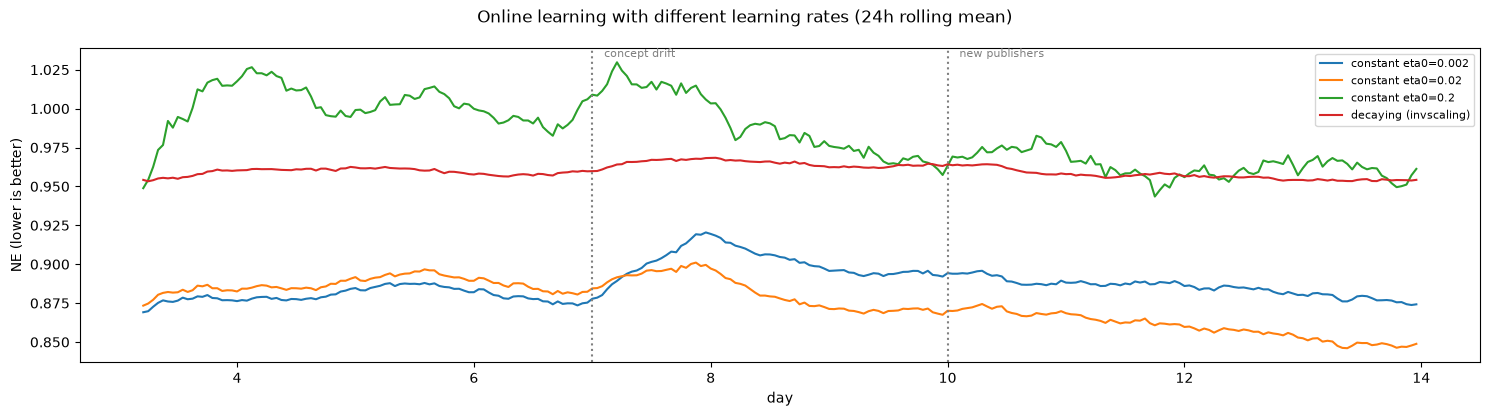

,NE | days 4-6 (selection),NE | before drift (days 4-7),NE | first 24h after drift,NE | last 3 days,NE | whole evaluation,AUC | last 3 days
constant eta0=0.002,0.8810,0.8796,0.9204,0.8808,0.8873,0.7405
constant eta0=0.02,0.8877,0.8864,0.8996,0.8543,0.8744,0.7648
constant eta0=0.2,1.0040,1.0045,1.0059,0.9587,0.9832,0.7317
decaying (invscaling),0.9601,0.9600,0.9682,0.9552,0.9599,0.6627


In [10]:
lr_runs = {f"constant eta0={lr}": run_online(initial_model, eta0=lr) for lr in [0.002, 0.02, 0.2]}
decaying = new_sgd(learning_rate="invscaling", eta0=CFG.learning_rate)       # step size shrinks over time
X0, y0 = vstack(X_stream[: CFG.warmup_hours]), np.concatenate(y_stream[: CFG.warmup_hours])
order = np.random.default_rng(0).permutation(len(y0))
for _ in range(CFG.retrain_epochs):
    decaying.partial_fit(X0[order], y0[order], classes=[0, 1])
lr_runs["decaying (invscaling)"] = run_online(decaying)

plot_runs(lr_runs, "Online learning with different learning rates (24h rolling mean)", metrics=("ne",))
lr_table = period_summary(lr_runs)
# What we could have known at decision time: NE during days 4-6 (before any drift)
lr_table.insert(0, "NE | days 4-6 (selection)", {n: df.loc[df["hour"] < 6 * 24, "ne"].mean() for n, df in lr_runs.items()})
lr_table.round(4)

Three lessons from this table:
1. A **too-large** step (0.2) is noisy and worse than the static model everywhere, and the **decaying** schedule is bad as well: it learns too little from the stream.
2. **The trap:** if we choose using only the quiet days 4-6 (first column), the *smallest* step (0.002) wins, because in a stable world the best thing to do is to change as little as possible. But after the drift it adapts much more slowly than 0.02 (compare the "first 24h after drift" and "last 3 days" columns).
3. So the learning rate must be chosen on historical data that **contains changes**: in practice teams replay several months of logs (with past incidents and seasonal shifts) and pick the setting that is good *across* them. That is why our config uses 0.02 rather than the "quiet-period winner".

In production you would also re-check this choice periodically with a **shadow** run (Section 12) rather than experimenting on live traffic.

---
## 11. Safeguard 2: data validation and rollback

An online model learns from **whatever** data arrives. That is its biggest risk. Two classic incidents:

1. **Tracking bug:** for 3 hours, every impression is logged as a click (CTR = 100%).
2. **Join bug:** for 12 hours, click labels are attached to the **wrong impressions** (labels shuffled). The CTR looks normal, so simple checks pass, but the data is garbage.

Two safeguards, each catching one of them:
- **Batch validation** before learning: is the batch CTR within a plausible range of the recent CTR? Are columns missing? If not, **skip** the update and alert.
- **Snapshot + rollback:** every few hours we save a copy of the model that was performing well (the *last known good* model). It keeps predicting in the background. If the live model becomes clearly worse than the snapshot for several hours in a row, we **roll back** to the snapshot.

In [11]:
CORRUPT_ALL_CLICKS = range(250, 253)          # tracking bug
CORRUPT_SHUFFLED = range(280, 292)            # join bug
rng_corrupt = np.random.default_rng(1)
y_corrupted = [y.copy() for y in y_stream]
for h in CORRUPT_ALL_CLICKS:
    y_corrupted[h][:] = 1
for h in CORRUPT_SHUFFLED:
    y_corrupted[h] = rng_corrupt.permutation(y_corrupted[h])


class SafeOnlineLearner:
    """Online learner with batch validation, periodic snapshots and automatic rollback."""

    def __init__(self, model, snapshot_every: int = 12, patience: int = 3, tolerance: float = 0.01):
        self.model = copy.deepcopy(model)
        self.snapshot = copy.deepcopy(model)          # last known good model
        self.snapshot_every, self.patience, self.tolerance = snapshot_every, patience, tolerance
        self.recent_ctr, self.worse_streak, self.events = [], 0, []

    def batch_is_valid(self, y: np.ndarray) -> bool:
        if len(self.recent_ctr) < 24:
            return True
        typical = np.median(self.recent_ctr[-72:])
        return 0.33 * typical <= y.mean() <= 3 * typical       # plausible CTR range

    def step(self, h: int, X, y_labels, y_true_for_eval) -> dict:
        # 1. Prequential evaluation of the live model AND the snapshot (shadow) on the new batch
        live = evaluate_batch(self.model, X, y_true_for_eval)
        shadow = evaluate_batch(self.snapshot, X, y_true_for_eval)
        # 2. Rollback check: live clearly worse than the snapshot for `patience` hours in a row?
        self.worse_streak = self.worse_streak + 1 if live["ne"] > shadow["ne"] + self.tolerance else 0
        if self.worse_streak >= self.patience:
            self.model, self.worse_streak = copy.deepcopy(self.snapshot), 0
            self.events.append((h, "ROLLBACK to snapshot"))
        # 3. Validate the batch, then learn (or skip)
        if self.batch_is_valid(y_labels):
            self.model.partial_fit(X, y_labels)
            self.recent_ctr.append(y_labels.mean())
        else:
            self.events.append((h, f"SKIPPED batch: CTR {y_labels.mean():.0%} looks impossible"))
        # 4. Take a new snapshot regularly, but only while the live model is healthy
        if h % self.snapshot_every == 0 and self.worse_streak == 0:
            self.snapshot = copy.deepcopy(self.model)
        return live | {"hour": h}


def run_with_labels(labels, safe: bool) -> tuple[pd.DataFrame, list]:
    """Online run where the model LEARNS from `labels` (possibly corrupted); evaluation always uses true labels."""
    if not safe:
        model, rows = copy.deepcopy(initial_model), []
        for h in EVAL_HOURS:
            rows.append(evaluate_batch(model, X_stream[h], y_stream[h]) | {"hour": h})
            model.partial_fit(X_stream[h], labels[h])
        return pd.DataFrame(rows), []
    learner = SafeOnlineLearner(initial_model)
    rows = [learner.step(h, X_stream[h], labels[h], y_stream[h]) for h in EVAL_HOURS]
    return pd.DataFrame(rows), learner.events


naive_df, _ = run_with_labels(y_corrupted, safe=False)
safe_df, safety_events = run_with_labels(y_corrupted, safe=True)
for h, event in safety_events:
    print(f"hour {h} (day {h / 24:.1f}): {event}")

hour 132 (day 5.5): ROLLBACK to snapshot
hour 250 (day 10.4): SKIPPED batch: CTR 100% looks impossible
hour 251 (day 10.5): SKIPPED batch: CTR 100% looks impossible
hour 252 (day 10.5): SKIPPED batch: CTR 100% looks impossible
hour 283 (day 11.8): ROLLBACK to snapshot
hour 286 (day 11.9): ROLLBACK to snapshot
hour 289 (day 12.0): ROLLBACK to snapshot
hour 292 (day 12.2): ROLLBACK to snapshot


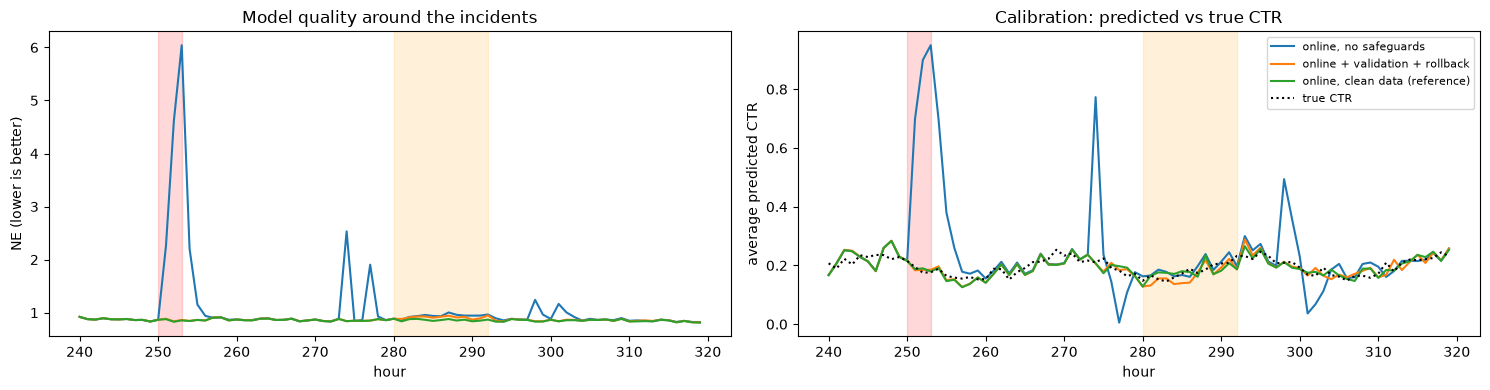

Mean NE from the first incident until 12h after the second one:
  no safeguards : 1.1770
  safeguards    : 0.8735
  clean data    : 0.8597


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
window = (naive_df["hour"] >= 240) & (naive_df["hour"] < 320)
for name, df in [("online, no safeguards", naive_df), ("online + validation + rollback", safe_df),
                 ("online, clean data (reference)", results["C: online (hourly)"])]:
    axes[0].plot(df.loc[window, "hour"], df.loc[window, "ne"], label=name)
    axes[1].plot(df.loc[window, "hour"], df.loc[window, "pred_ctr"], label=name)
axes[1].plot(naive_df.loc[window, "hour"], naive_df.loc[window, "true_ctr"], "k:", label="true CTR")
for ax in axes:
    for r, color in [(CORRUPT_ALL_CLICKS, "red"), (CORRUPT_SHUFFLED, "orange")]:
        ax.axvspan(r.start, r.stop, color=color, alpha=0.15)
    ax.set_xlabel("hour")
axes[0].set_ylabel("NE (lower is better)"); axes[1].set_ylabel("average predicted CTR")
axes[0].set_title("Model quality around the incidents"); axes[1].set_title("Calibration: predicted vs true CTR")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

incident = (naive_df["hour"] >= CORRUPT_ALL_CLICKS.start) & (naive_df["hour"] < CORRUPT_SHUFFLED.stop + 12)
print("Mean NE from the first incident until 12h after the second one:")
print(f"  no safeguards : {naive_df.loc[incident, 'ne'].mean():.4f}")
print(f"  safeguards    : {safe_df.loc[incident, 'ne'].mean():.4f}")
print(f"  clean data    : {results['C: online (hourly)'].loc[incident.values, 'ne'].mean():.4f}")

**What happened:**
- **Tracking bug (red):** without safeguards, three hours of "everyone clicked" push the model's predicted CTR far too high. For an ad network that means **over-bidding** on every impression until the model recovers. The validation check simply **skips** those batches.
- **Join bug (orange):** the CTR looks normal, so validation can't catch it. The shuffled labels teach the model that nothing predicts clicks, and its quality decays hour by hour. The event log shows the rollback kicking in a few hours into the incident and again every few hours while the bad data keeps coming. Rollback is slower than validation, because it needs a few hours of evidence, so **both** layers are needed.
- The safeguarded model ends up almost as good as a model trained on clean data (compare the three numbers above).
- Notice the **rollback on day 5.5** in the log: there was no incident then. With noisy hourly metrics, any automatic rule produces occasional **false alarms**. Here it was harmless (the snapshot was only a few hours old), which is why rollback targets should be recent snapshots and why `patience` and `tolerance` are tuning knobs.

In production, each of these events would also **page the on-call engineer**; safeguards buy time, they don't replace fixing the pipeline.

---
## 12. Safeguard 3: shadow deployment before promotion

Before letting an online-learning model make real bidding decisions, teams run it in **shadow mode**: it receives the same live traffic and makes predictions, but the predictions are only **logged**, not used. The current production model (here: the static model A) keeps serving. A pre-agreed **promotion rule** decides when the challenger takes over, for example:

> promote when the challenger's 24-hour rolling NE has been better than the champion's by at least 1% for 24 consecutive hours.

Since we already have the prequential results of both models, we can replay the decision.

In [13]:
def shadow_promotion(champion: pd.DataFrame, challenger: pd.DataFrame, margin: float = 0.01,
                     window: int = 24, required_hours: int = 24) -> int | None:
    """Return the first hour at which the challenger would be promoted (or None)."""
    champ = champion["ne"].rolling(window).mean()
    chall = challenger["ne"].rolling(window).mean()
    better = (chall < champ * (1 - margin)).astype(int)
    streak = better.groupby((better == 0).cumsum()).cumsum()           # consecutive hours of "better"
    hits = champion["hour"][streak >= required_hours]
    return int(hits.iloc[0]) if len(hits) else None


promotion_hour = shadow_promotion(results["A: static"], results["C: online (hourly)"])
if promotion_hour is None:
    print("The challenger was never clearly better: keep the champion.")
else:
    print(f"Challenger (online model) promoted at hour {promotion_hour} = day {promotion_hour / 24:.1f} "
          f"({promotion_hour - CFG.drift_hour} hours after the drift started)")

Challenger (online model) promoted at hour 197 = day 8.2 (29 hours after the drift started)


Before the drift the two models are equally good, so the rule (correctly) does **not** promote the challenger: there is no reason to take a risk. After the drift the challenger is clearly better and gets promoted about a day later. The 24-hour requirement is a deliberate trade-off between **speed** and **protection against flukes**.

---
## 13. Save the model with its metadata

For an online model, "the model" is a moving target, so we save **versioned snapshots** (e.g. every hour), each with metadata: which data it has seen, the feature configuration and the latest quality numbers. A rollback in production is then just "load snapshot N−1". In a real project these files go to object storage like `s3://models/ctr/2026-10-21T14/`; here we use a temporary folder.

In [14]:
production_model = copy.deepcopy(initial_model)
for h in EVAL_HOURS:                                                    # bring the online model up to date
    production_model.partial_fit(X_stream[h], y_stream[h])

ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="ctr_online_"))            # real project: versioned object storage
snapshot_name = f"ctr_sgd_hour{N_HOURS - 1:04d}.joblib"
joblib.dump({"model": production_model, "scaler": scaler}, ARTIFACT_DIR / snapshot_name)
metadata = {
    "model_name": "ctr_online_sgd", "snapshot": snapshot_name,
    "saved_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__, "last_hour_trained": N_HOURS - 1,
    "events_seen": int(sum(len(b) for b in stream)),
    "features": {"categorical": CATEGORICAL, "numeric": NUMERIC, "hash_features": CFG.hash_features,
                 "cross_features": ["site_id x device"]},
    "last_24h_prequential": results["C: online (hourly)"].tail(24)[["ne", "auc"]].mean().round(4).to_dict(),
    "config": asdict(CFG),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
for f in ARTIFACT_DIR.iterdir():
    print(f"{f.name:28s} {f.stat().st_size / 1024:9.1f} KB")

ctr_sgd_hour0335.joblib         2049.8 KB
metadata.json                      0.8 KB


Note the size: the weight vector has 2^18 entries no matter how many sites exist. That fixed size is another benefit of hashing.

---
## 14. Serve predictions with input validation

The ad server calls the model for every impression, with a strict latency budget (often < 10 ms). The service validates the request with Pydantic, builds the same hashed features as in training and returns a probability. Unknown publishers are fine thanks to hashing.

> Our simple Python service takes tens of milliseconds per call, mostly pandas and validation overhead (and this notebook runs on a busy shared machine). Real ad servers keep the weight vector in memory, compute the hashed dot product directly (only ~8 non-zero features per impression!) in compiled code, and score many candidates per call.

In [15]:
from typing import Literal, Optional
from pydantic import BaseModel, Field, ValidationError


class Impression(BaseModel):
    site_id: str = Field(min_length=1, max_length=64)
    app_category: Literal["news", "games", "shopping", "sports", "video", "finance", "travel"]
    device: Optional[Literal["ios", "android", "desktop"]] = None      # may be missing
    banner_pos: int = Field(ge=0, le=5)
    hour_of_day: int = Field(ge=0, le=23)
    past_clicks_7d: int = Field(ge=0, le=10_000)
    bid_price: float = Field(gt=0, le=1_000)


class CTRService:
    def __init__(self, artifact_dir: Path):
        meta = json.loads((artifact_dir / "metadata.json").read_text())
        bundle = joblib.load(artifact_dir / meta["snapshot"])
        self.model, self.scaler, self.version = bundle["model"], bundle["scaler"], meta["snapshot"]

    def predict(self, impressions: list[dict]) -> list[dict]:
        start = time.perf_counter()
        frame = pd.DataFrame([Impression(**i).model_dump() for i in impressions])   # raises on bad input
        proba = self.model.predict_proba(featurize(frame, self.scaler))[:, 1]
        latency_ms = (time.perf_counter() - start) * 1000
        return [{"p_click": round(float(p), 4), "model": self.version, "latency_ms": round(latency_ms, 2)}
                for p in proba]


service = CTRService(ARTIFACT_DIR)
request = {"site_id": "newsite_7", "app_category": "games", "device": "ios", "banner_pos": 0,
           "hour_of_day": 20, "past_clicks_7d": 3, "bid_price": 1.4}
print(service.predict([request, dict(request, device=None, banner_pos=2, past_clicks_7d=0)]))
try:
    service.predict([dict(request, hour_of_day=25, bid_price=-1)])
except ValidationError as err:
    print("Rejected:", [e["loc"][0] for e in err.errors()])

[{'p_click': 0.6837, 'model': 'ctr_sgd_hour0335.joblib', 'latency_ms': 24.94}, {'p_click': 0.1736, 'model': 'ctr_sgd_hour0335.joblib', 'latency_ms': 24.94}]
Rejected: ['hour_of_day', 'bid_price']


---
## 15. Automated sanity tests

In [16]:
def test_unseen_site_does_not_crash():
    out = service.predict([dict(request, site_id="never_seen_before_123")])[0]
    assert 0 < out["p_click"] < 1


def test_feature_space_is_fixed():
    assert featurize(stream[-1], scaler).shape[1] == featurize(stream[0], scaler).shape[1]


def test_validation_rejects_impossible_batch():
    learner = SafeOnlineLearner(initial_model)
    learner.recent_ctr = [0.09] * 48
    assert not learner.batch_is_valid(np.ones(1000))


def test_page_hinkley_detects_a_jump_and_ignores_noise():
    rng = np.random.default_rng(0)
    quiet = PageHinkley()
    assert not any(quiet.update(v) for v in rng.normal(0.9, 0.02, 200))
    jumpy = PageHinkley()
    assert any(jumpy.update(v) for v in np.r_[rng.normal(0.9, 0.02, 100), rng.normal(1.0, 0.02, 50)])


def test_online_beats_static_after_drift():
    assert comparison.loc["C: online (hourly)", "NE | last 3 days"] < comparison.loc["A: static", "NE | last 3 days"]


for test in [test_unseen_site_does_not_crash, test_feature_space_is_fixed, test_validation_rejects_impossible_batch,
             test_page_hinkley_detects_a_jump_and_ignores_noise, test_online_beats_static_after_drift]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_unseen_site_does_not_crash
PASSED  test_feature_space_is_fixed
PASSED  test_validation_rejects_impossible_batch
PASSED  test_page_hinkley_detects_a_jump_and_ignores_noise
PASSED  test_online_beats_static_after_drift


---
## 16. Summary, exercises and resources

| Industry practice | What we did | Where it's used |
|---|---|---|
| Hashing trick | `FeatureHasher`, fixed 2^18 space, cross feature | Ad click prediction, spam filters, Vowpal Wabbit |
| Frozen scaler | `StandardScaler` fitted on warm-up only | Any SGD model on numeric inputs |
| Prequential evaluation | Test-then-train on every hourly batch | Stream-learning benchmarks, live monitoring |
| Normalized entropy | Log-loss relative to the base rate | Facebook / Meta ads, CTR teams |
| Update strategies | Static vs nightly retrain vs `partial_fit` vs drift-triggered | Recommenders, ads, fraud, demand forecasting |
| Drift detection | Page-Hinkley on NE | Monitoring dashboards, retrain triggers |
| Learning-rate choice | Constant vs decaying, chosen on early data only | Every online learner |
| Data validation | CTR plausibility check, skip bad batches | Pipeline "circuit breakers" |
| Rollback | Last-known-good snapshot running in shadow | Online models, feature pipelines |
| Shadow deployment | Promotion rule on rolling NE | Safe launches of new models |

### Practice exercises
1. Change `drift_hour` to day 5 and `new_sites_hour` to day 12. Which strategy suffers most?
2. Lower `hash_features` to 2^10. How much do collisions hurt the AUC?
3. Add a "gradual drift": make the games boost grow slowly from day 7 to day 12. Does Page-Hinkley still fire? Try a smaller `threshold`.
4. Combine B and C: retrain from scratch every night **and** apply `partial_fit` during the day. Is it better than C alone?
5. Install `river` (`pip install river==0.25.0`, as pinned in `requirements.txt`) and replace our `PageHinkley` class with `river.drift.PageHinkley` or `river.drift.ADWIN`.

### Resources (checked)
- scikit-learn example "Out-of-core classification of text documents" (`partial_fit` + `HashingVectorizer`): https://scikit-learn.org/stable/auto_examples/applications/plot_out_of_core_classification.html
- scikit-learn user guide, incremental learning / `partial_fit`: https://scikit-learn.org/stable/computing/scaling_strategies.html
- He et al., *Practical Lessons from Predicting Clicks on Ads at Facebook* (normalized entropy, data freshness, online learning): https://research.facebook.com/publications/practical-lessons-from-predicting-clicks-on-ads-at-facebook/
- Gama et al., *On evaluating stream learning algorithms* (prequential evaluation): https://link.springer.com/article/10.1007/s10994-012-5320-9
- River (online ML library, drift detectors): https://riverml.xyz/
- Kaggle "Avazu Click-Through Rate Prediction" (real CTR data with hashed ids): https://www.kaggle.com/c/avazu-ctr-prediction

### Related notebooks in this repo
- Theory and `river`: `01_online_learning.ipynb`
- Drift monitoring with PSI: `../01_supervised/14_industry_churn_prediction.ipynb`
- Model monitoring in MLOps: `../../15_MLOps/06_monitoring/01_monitoring.ipynb`
- Scheduling retraining: `../../15_MLOps/03_pipeline_orchestration/01_orchestration.ipynb`